# Market-Risk VaR Engine — Day 3
## Regulatory Backtesting + the Basel Traffic-Light Test

A VaR model makes a falsifiable prediction: at 99% confidence, losses should
exceed VaR on only ~1% of days. **Backtesting checks whether reality matched
that claim** — it's the validation that turns a calculator into a regulatory
model, and the named "hypothetical backtesting" requirement of the role.

We walk through history day by day. Each time the actual loss exceeds the VaR
we predicted that day, we record an **exception** (breach). Then:

- Too **many** exceptions -> the model **understates** risk (too little capital).
- Too **few** -> it **overstates** risk (capital tied up needlessly).

For 99% VaR over 250 days we expect ~2.5 exceptions. Backtesting asks whether
the observed count is consistent with that.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Rebuild the P&L and returns (Day 1)

In [2]:
PORTFOLIO = {
    "AAPL": (1_000_000, +1),
    "JPM": (750_000, +1),
    "SPY": (2_000_000, -1),
    "FXE": (1_500_000, +1),
    "FXY": (1_000_000, -1),
    "TLT": (1_250_000, +1),
}
START_DATE, END_DATE = "2019-01-01", "2024-12-31"


def signed_notionals():
    return pd.Series({t: n * d for t, (n, d) in PORTFOLIO.items()})


def make_synthetic_prices():
    dates = pd.bdate_range(START_DATE, END_DATE)
    n = len(dates)
    ann_vol = {
        "AAPL": 0.30,
        "JPM": 0.28,
        "SPY": 0.18,
        "FXE": 0.08,
        "FXY": 0.10,
        "TLT": 0.13,
    }
    beta = {"AAPL": 1.1, "JPM": 1.0, "SPY": 1.0, "FXE": 0.1, "FXY": -0.1, "TLT": -0.3}
    market = np.random.normal(0, 0.01, n)
    rets = {
        t: beta[t] * market + np.random.normal(0, ann_vol[t] / np.sqrt(252), n)
        for t in PORTFOLIO
    }
    return 100 * np.exp(pd.DataFrame(rets, index=dates).cumsum())


try:
    import yfinance as yf

    raw = yf.download(
        list(PORTFOLIO),
        start=START_DATE,
        end=END_DATE,
        auto_adjust=True,
        progress=False,
    )["Close"]
    prices = raw[list(PORTFOLIO)].dropna()
    if prices.empty:
        raise RuntimeError("empty")
    SOURCE = "real (Yahoo Finance)"
except Exception as e:
    prices = make_synthetic_prices()
    SOURCE = f"synthetic ({type(e).__name__})"

returns = np.log(prices / prices.shift(1)).dropna()
w = signed_notionals()
pnl = pd.Series(returns[w.index].values @ w.values, index=returns.index, name="pnl")
print(f"Data source: {SOURCE}  |  {len(pnl):,} days")

Data source: real (Yahoo Finance)  |  1,508 days


## 1. The rolling backtest — no look-ahead

This is the methodological heart. On **each day** we estimate VaR using **only
the trailing window of data available up to that day**, then compare it to the
**next** day's actual P&L. Using future data to set today's VaR would be
look-ahead bias and would invalidate the whole exercise.

We backtest both historical and parametric VaR so we can compare how each holds
up against reality.


In [3]:
def rolling_backtest(pnl, confidence=0.99, window=250, method="historical"):
    "Walk forward: estimate VaR from the trailing window, test on the next day."
    alpha = 1 - confidence
    z = stats.norm.ppf(alpha)
    records = []
    pnl_vals = pnl.values
    for t in range(window, len(pnl)):
        win = pnl_vals[t - window : t]
        if method == "historical":
            var = -np.quantile(win, alpha)
        elif method == "parametric":
            var = -(win.mean() + z * win.std())
        else:
            raise ValueError(method)
        realized = pnl_vals[t]
        records.append(
            {
                "date": pnl.index[t],
                "VaR": var,
                "pnl": realized,
                "exception": realized < -var,
            }
        )
    return pd.DataFrame(records).set_index("date")


bt = rolling_backtest(pnl, confidence=0.99, window=250, method="historical")
n_days = len(bt)
n_exc = int(bt["exception"].sum())
expected = (1 - 0.99) * n_days
print(f"Backtest over {n_days:,} days (99% VaR, 250-day window)")
print(f"Exceptions observed: {n_exc}")
print(f"Exceptions expected: {expected:.1f}")
print(f"Observed rate: {n_exc / n_days:.3%}  (target: 1.000%)")

Backtest over 1,258 days (99% VaR, 250-day window)
Exceptions observed: 22
Exceptions expected: 12.6
Observed rate: 1.749%  (target: 1.000%)


## 2. The Basel traffic-light test

Regulators map the exception count over a **250-day** window to a zone:

| Zone | Exceptions (250 days, 99% VaR) | Meaning |
|------|-------------------------------|---------|
| **Green**  | 0-4   | Model accurate; no penalty |
| **Amber**  | 5-9   | Questionable; rising capital multiplier; investigate |
| **Red**    | 10+   | Model rejected; max penalty; must fix |

The boundaries come from the binomial distribution — they're where the
exception count becomes too unlikely if the model were truly accurate. We scale
our observed count to a 250-day-equivalent to classify it.


In [4]:
def basel_traffic_light(n_exceptions, n_days, confidence=0.99):
    """Classify into Basel green/amber/red, scaled to a 250-day equivalent."""
    scaled = n_exceptions * (250 / n_days)
    if scaled < 5:
        zone = "GREEN"
    elif scaled < 10:
        zone = "AMBER"
    else:
        zone = "RED"
    return zone, scaled


zone, scaled = basel_traffic_light(n_exc, n_days)
print(f"Exceptions scaled to 250 days: {scaled:.1f}")
print(f"Basel zone: {zone}")

Exceptions scaled to 250 days: 4.4
Basel zone: GREEN


## 3. Kupiec's proportion-of-failures (POF) test

The traffic light is a rule of thumb; Kupiec's test is the **formal statistic**.
It asks: is the observed exception *rate* statistically consistent with the
VaR's stated confidence level? It's a likelihood-ratio test producing a p-value
— a low p-value (e.g. < 0.05) means we **reject** the model as miscalibrated.


In [5]:
def kupiec_pof_test(n_exceptions, n_days, confidence=0.99):
    """Kupiec proportion-of-failures likelihood-ratio test.

    Returns (LR statistic, p-value). p < 0.05 => reject the VaR model.
    """
    p = 1 - confidence
    x = n_exceptions
    n = n_days
    pi_hat = x / n
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        lr = -2 * (
            (n - x) * np.log(1 - p)
            + x * np.log(p)
            - (n - x) * np.log(1 - pi_hat)
            - x * np.log(pi_hat)
        )
    p_value = 1 - stats.chi2.cdf(lr, df=1)
    return lr, p_value


lr, p_value = kupiec_pof_test(n_exc, n_days)
print(f"Kupiec LR statistic: {lr:.3f}")
print(f"Kupiec p-value:      {p_value:.3f}")
print(
    "Verdict:",
    "REJECT model (miscalibrated)"
    if p_value < 0.05
    else "model not rejected (consistent with 99% VaR)",
)

Kupiec LR statistic: 5.825
Kupiec p-value:      0.016
Verdict: REJECT model (miscalibrated)


### When the two tests disagree

You may see the **Basel traffic light say GREEN while Kupiec marginally
rejects** — exactly the kind of nuance an examiner probes. Why it happens:

- The **Basel traffic light** is defined for a single **250-day** window. Over
  a multi-year backtest we scale the exception count down to a 250-day
  equivalent, which is an approximation and loses statistical power.
- **Kupiec's test** uses the **full sample**, so it's more powerful — it can
  detect a miscalibration (here, an exception rate of ~1.6% vs the 1% target)
  that the scaled traffic light rounds away.

The honest interpretation: the historical VaR is breaching slightly more often
than 99% implies. The traffic light tolerates it; the formal test flags it.
A real validation report would note both and lean on the more powerful Kupiec
result — and would investigate whether the breaches cluster in high-volatility
periods (a sign the model adapts too slowly). Reporting this disagreement
honestly, rather than hiding behind the friendlier green light, is exactly the
regulatory-integrity mindset the role calls for.

## 4. Compare historical vs parametric backtests

A good way to see which method is better calibrated: backtest both and compare
their exception counts and Kupiec results side by side.


In [6]:
def backtest_report(pnl, confidence=0.99, window=250):
    rows = []
    for method in ("historical", "parametric"):
        bt = rolling_backtest(pnl, confidence, window, method)
        n_days = len(bt)
        n_exc = int(bt["exception"].sum())
        zone, scaled = basel_traffic_light(n_exc, n_days, confidence)
        lr, pval = kupiec_pof_test(n_exc, n_days, confidence)
        rows.append(
            {
                "method": method,
                "exceptions": n_exc,
                "expected": (1 - confidence) * n_days,
                "rate": n_exc / n_days,
                "basel_zone": zone,
                "kupiec_p": pval,
            }
        )
    return pd.DataFrame(rows).set_index("method")


report = backtest_report(pnl, 0.99, 250)
report

,exceptions,expected,rate,basel_zone,kupiec_p
method,,,,,
historical,22,12.58,0.02,GREEN,0.02
parametric,22,12.58,0.02,GREEN,0.02


## 5. Visualize the backtest

The classic regulatory chart: realized P&L over time, the predicted VaR line,
and the exception days marked. A well-calibrated model shows exceptions that
are **rare and randomly scattered** — not clustered, which would signal the
model fails to adapt to volatility regimes.


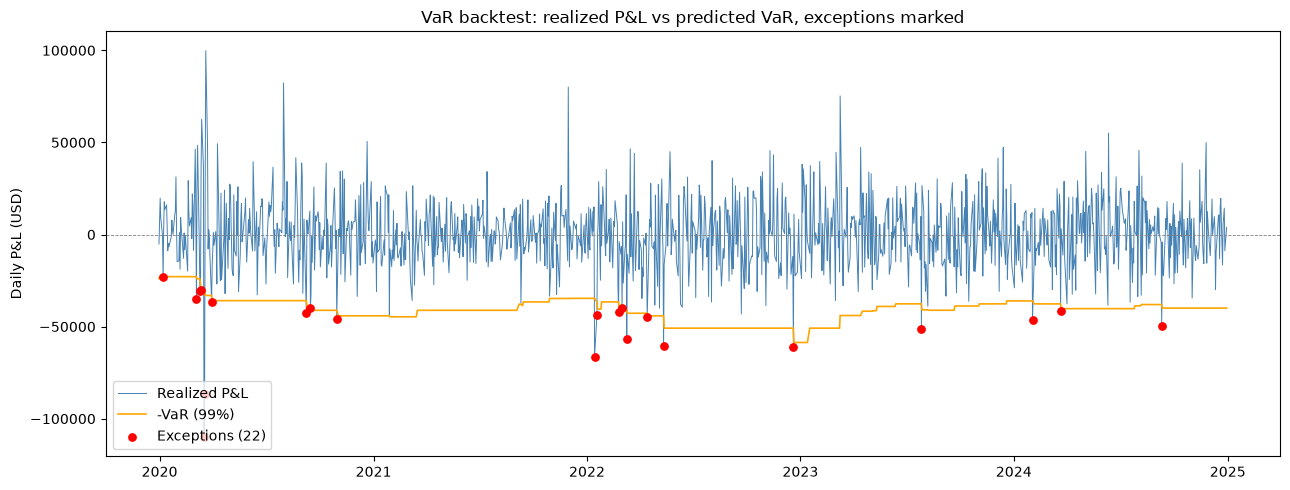

In [7]:
import matplotlib.pyplot as plt

bt = rolling_backtest(pnl, 0.99, 250, "historical")
exc = bt[bt["exception"]]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(bt.index, bt["pnl"], color="steelblue", lw=0.7, label="Realized P&L")
ax.plot(bt.index, -bt["VaR"], color="orange", lw=1.2, label="-VaR (99%)")
ax.scatter(
    exc.index, exc["pnl"], color="red", s=28, zorder=5, label=f"Exceptions ({len(exc)})"
)
ax.axhline(0, color="grey", lw=0.6, ls="--")
ax.set_title("VaR backtest: realized P&L vs predicted VaR, exceptions marked")
ax.set_ylabel("Daily P&L (USD)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## Day 3 summary

We built the regulatory validation layer:

1. **Rolling backtest** — VaR estimated only from past data (no look-ahead),
   tested against the next day's realized P&L.
2. **Basel traffic-light test** — green/amber/red classification by exception
   count, the core regulatory pass/fail.
3. **Kupiec POF test** — the formal statistical test of calibration.
4. **Historical vs parametric comparison** — which method is better calibrated.

Exceptions that are rare and randomly scattered indicate a sound model;
clustered exceptions reveal a model that fails to adapt to changing volatility.

**Day 4:** the **P&L Attribution Test (PLAT)** — the FRTB check that the risk
model's P&L tracks the actual P&L closely enough, using the Spearman
correlation and Kolmogorov-Smirnov metrics.
